import os is for working with files, such as checking whether a file exists or getting its size.
import urllib.request is for downloading files from the internet.
import numpy as np loads numpy. as np is a short nickname, so we write np.something.
import matplotlib.pyplot as plt loads the plotting tool, nicknamed plt.
import rasterio loads the map-file reader.

In [1]:
!pip install -q rasterio
import os
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import rasterio
print("done") 


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


done


Now will doanload the data from Nasa
surf.tif - is the evaluation map each pixel holds surface height Z in meters
slp.tif - Nasa's own slope map

In [2]:
base = "https://pgda.gsfc.nasa.gov/data/LOLA_5mpp/Site04/" #NASA web folder
files = {
    "site04.tif":     "Site04_final_adj_5mpp_surf.tif", #elevation
    "site04_slp.tif": "Site04_final_adj_5mpp_slp.tif",  #slope
}

In [3]:
for local_name, remote_name in files.items(): #for loop to search
    if os.path.exists(local_name): #with os searching to the name
        print(local_name,"downloaded") #if there print
    else:
        print("Downloading",local_name) #else print downlaodding
        urllib.request.urlretrieve(base + remote_name, local_name) #downloadt trough the internet

site04.tif downloaded
site04_slp.tif downloaded


In [4]:
for name in files:
    print(name,round(os.path.getsize(name)/ 1e6,1),"MB") #here the getsize gives the size in bytes and 1e6 is onemillon to the MB

site04.tif 41.0 MB
site04_slp.tif 41.0 MB


In [5]:
with rasterio.open("site04.tif") as src: #it opens the file and close 
    dem = src.read(1).astype("float64") #
    pixel_size = src.res[0]


In [6]:
print("Shape:", dem.shape)
print("Pixel size (m):", pixel_size)
print("Lowest / highest point (m):", round(dem.min()), round(dem.max()))

Shape: (3200, 3200)
Pixel size (m): 5.0
Lowest / highest point (m): -2848 1805


What it means: the map is 3200 × 3200 pixels, and each pixel is 5 m, so it covers 16 km × 16 km of the Moon. Heights range from about −2.8 km to +1.8 km. The difference, about 4.6 km, is the depth of Shackleton crater.

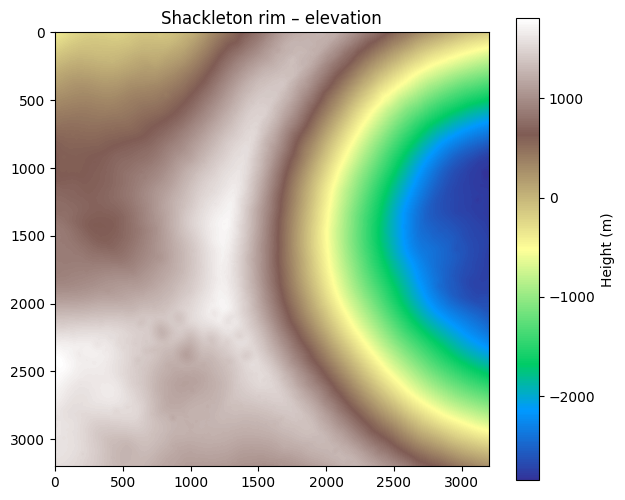

In [7]:
plt.figure(figsize=(7, 6)) #pic size 
plt.imshow(dem, cmap="terrain") #low areas blue and high areas brown and white
plt.colorbar(label="Height (m)") #scale bar shows the mm to the color
plt.title("Shackleton rim – elevation")
plt.show()

In [12]:
dz_dy, dz_dx = np.gradient(dem,pixel_size) #this check for every pixel at once how much the hight change per meter going east and north 
slope_deg = np.degrees(np.arctan(np.sqrt(dz_dy**2 + dz_dx**2)))  #convert one steepness num the east and north with it pyhtogoras
#by arctan convert the steepness in to radians angle 
#by desgrees convert radians in to desgrees
print("Slope range (deg):", round(slope_deg.min(), 2), "to", round(slope_deg.max(), 1))

Slope range (deg): 0.01 to 69.6


In [13]:
with rasterio.open("site04_slp.tif") as src:
    nasa_slope = src.read(1).astype("float64")
print("Median difference (deg):", np.median(np.abs(slope_deg - nasa_slope)))

Median difference (deg): 0.00010364114522332102


In [14]:
safe = slope_deg < 8
print("Safe area: %.1f%%" % (100 * safe.mean()))

Safe area: 12.1%


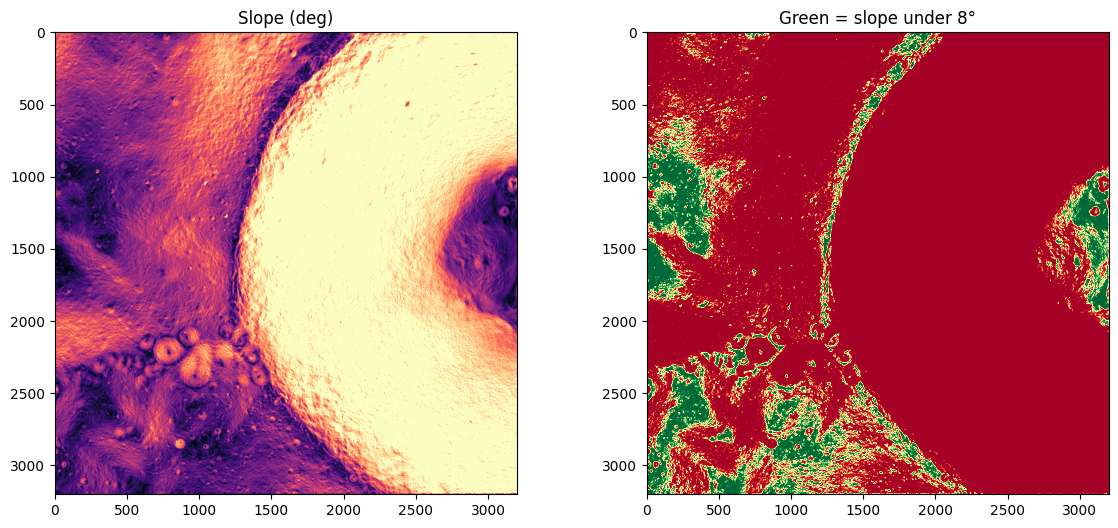

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6)) #make the 2 pic side by side 
ax[0].imshow(slope_deg, cmap="magma", vmax=30); ax[0].set_title("Slope (deg)") #1 img here anything steeper than 30 the clors are brighter
ax[1].imshow(safe, cmap="RdYlGn");             ax[1].set_title("Green = slope under 8°") #red to green mao true tone true is green false is ref
plt.show()